# Mi primer ejercicio

En este notebook se van a cargar datos de elevaciones y se mostrará algunos de ellos.

In [8]:
# Importa las librerías
import xarray as xr
import scipy.io as sio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
# Abrir archivo NetCDF
datos = sio.loadmat("bati_gebco_oaxaca.mat")

# Mostrar información del archivo
print(datos.keys())

dict_keys(['__header__', '__version__', '__globals__', 'lon', 'lat', 'H'])


In [12]:
#Se consulta las dimesiones de las variables

for nombre, contenido in datos.items():
    if not nombre.startswith("__"):
        print(nombre, contenido.shape)

lon (1, 662)
lat (1, 506)
H (506, 662)


In [14]:
# Extraer la matriz de batimetría
batimetria = datos["H"]

# Mostrar las primeras 5 filas y 5 columnas
print(batimetria[:5, :5])

[[-2741 -2674 -2660 -2739 -2881]
 [-2684 -2606 -2570 -2620 -2814]
 [-2651 -2554 -2509 -2632 -2798]
 [-2677 -2618 -2614 -2713 -2856]
 [-2721 -2679 -2691 -2788 -2905]]


In [15]:
# Visualizar al inicio y al final de la base de datos
print(batimetria[:, :5])

[[-2741 -2674 -2660 -2739 -2881]
 [-2684 -2606 -2570 -2620 -2814]
 [-2651 -2554 -2509 -2632 -2798]
 ...
 [  904   861   871   935  1013]
 [  829   820   872   955   986]
 [  807   833   993  1169  1240]]


In [16]:
# Estadísticos básicos
print("Valor mínimo:", float(batimetria.min()))
print("Valor máximo:", float(batimetria.max()))
print("Valor promedio:", float(batimetria.mean()))

Valor mínimo: -6721.0
Valor máximo: 3630.0
Valor promedio: -976.9644686720084


In [17]:
# Extraer coordenadas como vectores 1D
lon = datos["lon"].squeeze()
lat = datos["lat"].squeeze()

print("lon:", lon.shape, "rango:", lon.min(), "a", lon.max())
print("lat:", lat.shape, "rango:", lat.min(), "a", lat.max())
print("H:", batimetria.shape)

lon: (662,) rango: -98.66666666666667 a -93.15
lat: (506,) rango: 13.833333333333329 a 18.049999999999997
H: (506, 662)


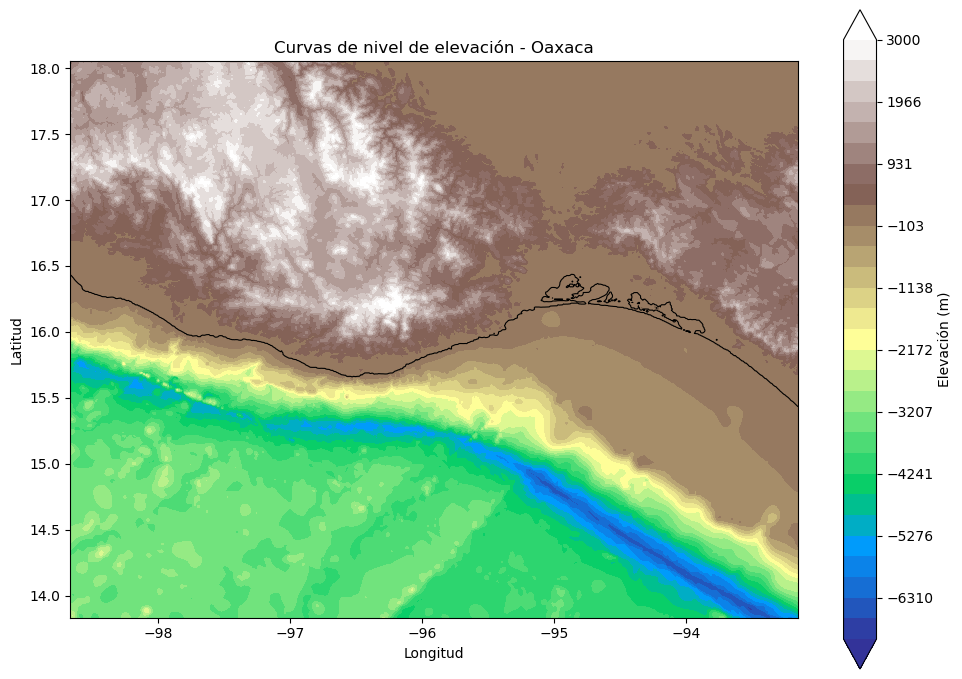

In [18]:
#Se establece las dimesiones de la figura
fig, ax = plt.subplots(figsize=(10, 7))

# se establecen los valores mínimos y máximo para establecer escala
niveles = np.linspace(-7000, 3000, 30)
cf = ax.contourf(lon, lat, batimetria,
                 levels=niveles,
                 cmap="terrain",
                 extend="both")

# Línea de costa (nivel 0 m)
ax.contour(lon, lat, batimetria, levels=[0], colors="black", linewidths=0.8)

fig.colorbar(cf, ax=ax, label="Elevación (m)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Curvas de nivel de elevación - Oaxaca")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()